# CLFG · WY2026 SNOWPACK results

CLFG is on Mendenhall Glacier. The only field observation is approximately **2 m of snow on 25 May 2026**. The observation has no recorded time of day, so the comparison uses May 25 in Juneau local time. Treat model–observation differences as descriptive for this single approximate measurement.

All four runs start snow-free on flat terrain and use the radar-site configuration with the soil model off, ground temperature fixed at 0 °C, and a 1.2 °C rain–snow threshold. The corrected runs use **0.60, 0.50, and 0.47 °C per 100 m** and the same ArcticDEM site elevation. Since CLFG is below the grid cell, the three rates warm the forcing by +2.27, +1.89, and +1.78 °C, respectively. All four runs use the available WY2026 forcing through 29 September. The full modeled column can be compared with the field depth, with no older glacier layers supplied at initialization.

Run `python sites/clfg/scripts/run_clfg.py` from the repository root to prepare and run both cases in a new model directory. An alternate `--output-root` allows repeat runs. Set `CLFG_MODEL_SITE` to the resulting site directory to review an alternate run.

Run `python sites/clfg/scripts/run_clfg.py --lapse-rate 0.5` or `python sites/clfg/scripts/run_clfg.py --lapse-rate 0.47` for a sensitivity case. Use `--output-root` for a repeat run and set `CLFG_SENSITIVITY_SITE` to the directory containing both sensitivity runs.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'sites/clfg/site_info.txt').is_file()), None)
if root is None:
    raise RuntimeError('Open from inside jif_snow_modeling')
sys.path.insert(0, str(root / 'sites/radar_sites/scripts'))
from prepare_radar_site_forcing import MODEL_ROOT, read_smet
from visualization import OBSERVATION_COLOR, RC_PARAMS, SIMULATION_COLORS, SIMULATION_LABELS

plt.rcParams.update(RC_PARAMS)
info = dict(line.split(': ', 1) for line in (root / 'sites/clfg/site_info.txt').read_text().splitlines())
observed_depth = float(info['Snow depth'].split()[1])
local_timezone = 'America/Juneau'
observation_day = pd.Timestamp(info['Observation date'], tz=local_timezone)
next_day = observation_day + pd.Timedelta(days=1)
site_dir = Path(os.environ.get('CLFG_MODEL_SITE', MODEL_ROOT / 'clfg')).expanduser()
metadata_path = site_dir / 'input/hrrrak_WY2026/hrrrak_clfg_WY2026.json'
metadata = json.loads(metadata_path.read_text())
expected = pd.date_range(metadata['start_UTC'], metadata['end_UTC'], freq='h')

sensitivity_site = Path(os.environ.get('CLFG_SENSITIVITY_SITE', site_dir)).expanduser()
run_labels = {
    'hrrrak': SIMULATION_LABELS['hrrrak'],
    'hrrrak_lapserate': 'HRRR-AK · 0.6 °C per 100 m',
    'hrrrak_lapserate_0p5': 'HRRR-AK · 0.50 °C per 100 m',
    'hrrrak_lapserate_0p47': 'HRRR-AK · 0.47 °C per 100 m',
}
sensitivity_colors = {
    'hrrrak_lapserate_0p5': 'darkorange',
    'hrrrak_lapserate_0p47': 'seagreen',
}
run_colors = {**SIMULATION_COLORS, **sensitivity_colors}
models = {}
for forcing in run_labels:
    directory = sensitivity_site if forcing in sensitivity_colors else site_dir
    path = directory / 'output' / f'{forcing}_clfg_WY2026_heatflux_soiltemp_zero.smet'
    header, frame = read_smet(path, ['timestamp', 'HS_mod', 'SWE'])
    fields = header['fields'].split()
    multipliers = header['units_multiplier'].split()
    depth_scale, swe_scale = (float(multipliers[fields.index(field)]) for field in ('HS_mod', 'SWE'))
    if (depth_scale, swe_scale) != (0.01, 1.0):
        raise ValueError(f'Unexpected depth or SWE units in {path}')
    if not frame.index.equals(expected) or frame.isna().any().any():
        raise ValueError(f'Incomplete hourly output: {path}')
    frame.index = frame.index.tz_localize('UTC').tz_convert(local_timezone)
    models[forcing] = frame.assign(depth_m=frame.HS_mod * depth_scale, swe_mm=frame.SWE * swe_scale)

print(f"Site elevation {metadata['elevation_m']:.1f} m · HRRR-AK elevation "
      f"{metadata['hrrr_elevation_min_m']:.1f} m · temperature correction "
      f"{metadata['correction_min_K']:+.2f} °C")
print(f"{len(expected):,} hourly outputs per run · {expected[0]} to {expected[-1]} UTC")


Site elevation 652.0 m · HRRR-AK elevation 1030.0 m · temperature correction +2.27 °C
8,717 hourly outputs per run · 2025-10-01 00:00:00 to 2026-09-29 04:00:00 UTC


In [2]:
rows = []
for forcing, frame in models.items():
    day = frame.loc[(frame.index >= observation_day) & (frame.index < next_day), 'depth_m']
    if len(day) != 24:
        raise ValueError(f'Expected 24 local observation-day hours for {forcing}')
    rows.append({
        'Run': run_labels[forcing],
        'Mean (m)': day.mean(),
        'Minimum (m)': day.min(),
        'Maximum (m)': day.max(),
        'Mean minus approximate observation (m)': day.mean() - observed_depth,
    })
display(pd.DataFrame(rows).set_index('Run').round(2))


,Mean (m),Minimum (m),Maximum (m),Mean minus approximate observation (m)
Run,,,,
HRRR-AK Raw,6.02,6.00,6.03,4.02
HRRR-AK · 0.6 °C per 100 m,1.26,1.24,1.28,-0.74
HRRR-AK · 0.50 °C per 100 m,1.83,1.81,1.84,-0.17
HRRR-AK · 0.47 °C per 100 m,2.04,2.02,2.06,0.04


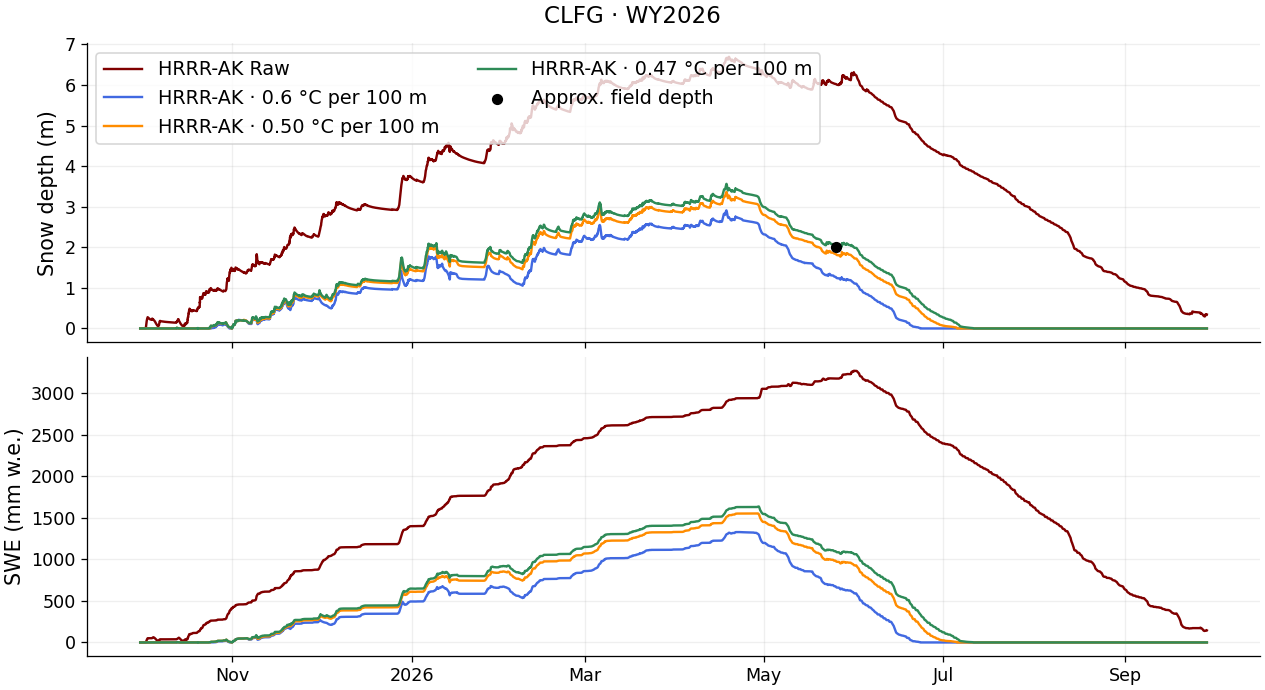

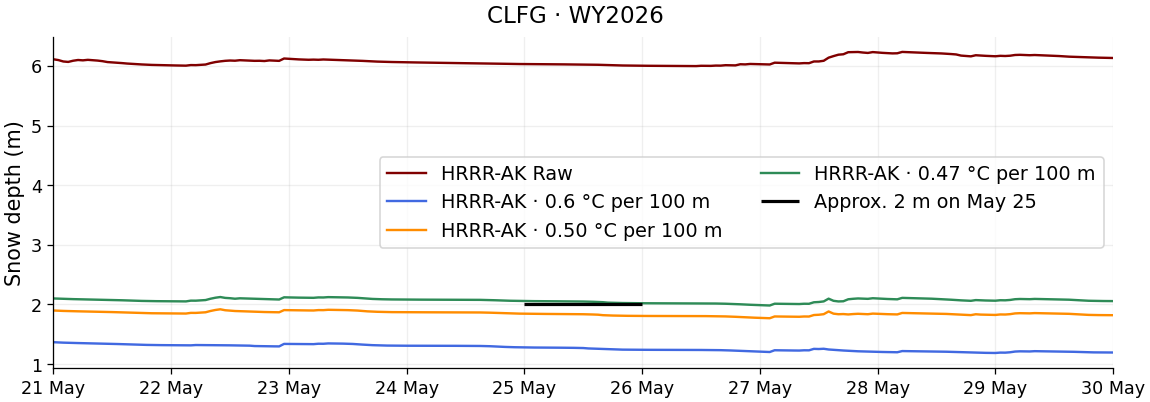

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout='constrained')
for forcing, frame in models.items():
    for ax, field in zip(axes, ('depth_m', 'swe_mm')):
        ax.plot(frame.index, frame[field], color=run_colors[forcing],
                label=run_labels[forcing])
axes[0].scatter(observation_day + pd.Timedelta(hours=12), observed_depth,
                color=OBSERVATION_COLOR, label='Approx. field depth', zorder=3)
axes[0].set(ylabel='Snow depth (m)')
axes[1].set(ylabel='SWE (mm w.e.)')
locator = mdates.AutoDateLocator(tz=local_timezone)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=local_timezone))
axes[0].legend(ncols=2)
for ax in axes:
    ax.grid(alpha=.2)
plt.gcf().suptitle('CLFG · WY2026')
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5), layout='constrained')
start, end = observation_day - pd.Timedelta(days=4), next_day + pd.Timedelta(days=4)
for forcing, frame in models.items():
    ax.plot(frame.depth_m.loc[start:end], color=run_colors[forcing],
            label=run_labels[forcing])
ax.hlines(observed_depth, observation_day, next_day, color=OBSERVATION_COLOR,
          linewidth=2, label='Approx. 2 m on May 25')
ax.set(xlim=(start, end), ylabel='Snow depth (m)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b', tz=local_timezone))
ax.legend(ncols=2)
ax.grid(alpha=.2)
plt.gcf().suptitle('CLFG · WY2026')
plt.show()


## Seasonal snow depth and the May 25 comparison

The lower panel compares mean modeled snow depth over May 25 in Juneau local time with the approximate 2 m field reading. Whiskers show the minimum and maximum modeled hourly depths that day.

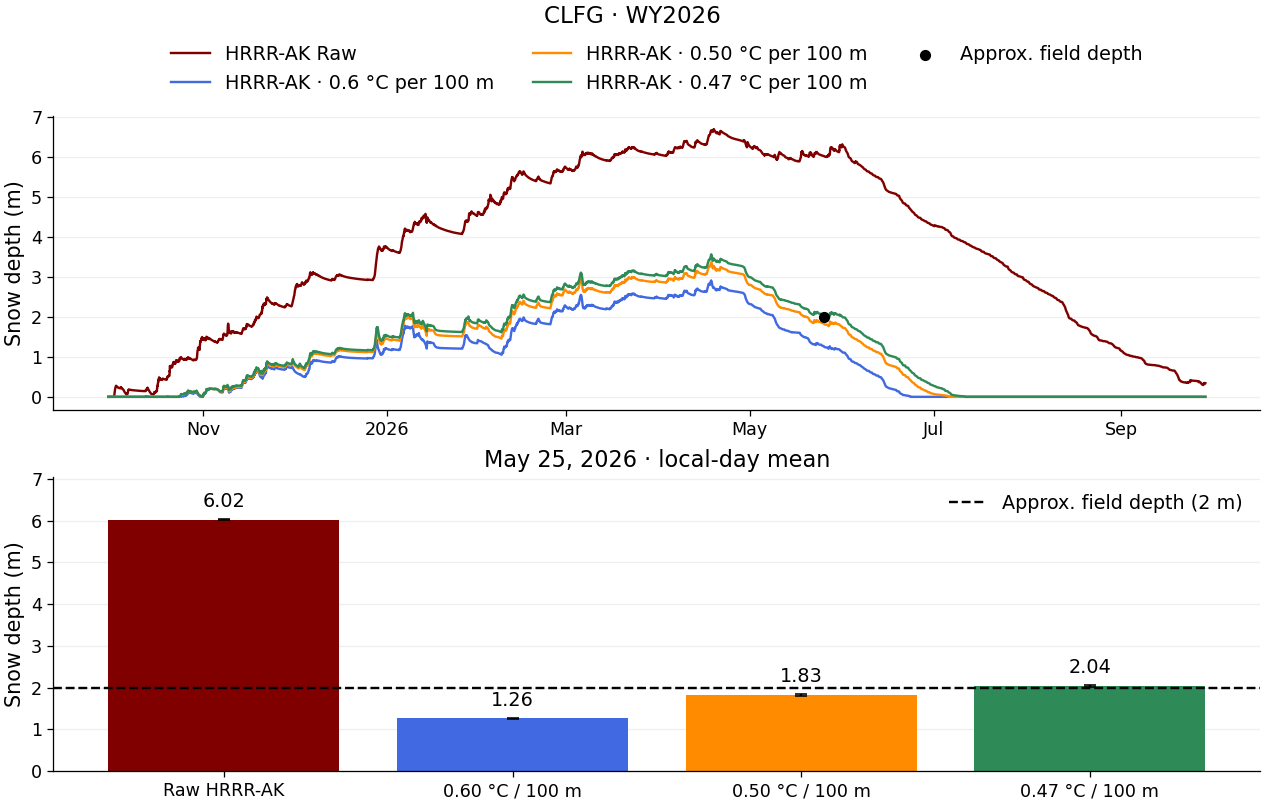

In [ ]:
fig_observation, (season_ax, day_ax) = plt.subplots(
    2, 1, figsize=(11, 7), layout='constrained'
)
for forcing, frame in models.items():
    season_ax.plot(frame.index, frame.depth_m, color=run_colors[forcing],
                   label=run_labels[forcing])
season_ax.scatter(observation_day + pd.Timedelta(hours=12), observed_depth,
                  color=OBSERVATION_COLOR, label='Approx. field depth', zorder=3)
locator = mdates.AutoDateLocator(tz=local_timezone)
season_ax.xaxis.set_major_locator(locator)
season_ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=local_timezone))
season_ax.set(ylabel='Snow depth (m)')
season_ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02),
                 ncols=3, frameon=False)

day_summary = pd.DataFrame(rows).set_index('Run').loc[list(run_labels.values())]
means = day_summary['Mean (m)']
positions = range(len(means))
bars = day_ax.bar(positions, means, color=[run_colors[forcing] for forcing in run_labels],
                  yerr=[means - day_summary['Minimum (m)'],
                        day_summary['Maximum (m)'] - means], capsize=4)
day_ax.bar_label(bars, fmt='%.2f', padding=5)
day_ax.axhline(observed_depth, color=OBSERVATION_COLOR, linestyle='--',
               label=f'Approx. field depth ({observed_depth:g} m)')
day_ax.set(title=f'{observation_day:%B %d, %Y} · local-day mean',
           xticks=positions, xticklabels=['Raw HRRR-AK', '0.60 °C / 100 m',
                                         '0.50 °C / 100 m', '0.47 °C / 100 m'],
           ylabel='Snow depth (m)', ylim=(0, 1.17 * max(observed_depth, day_summary['Maximum (m)'].max())))
day_ax.legend(frameon=False)
for ax in (season_ax, day_ax):
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
plt.gcf().suptitle('CLFG · WY2026')
plt.show()
